# Day 31/84
# Machine Learning Workflow Basics

In [ ]:
# Install required packages
!pip install scikit-learn numpy matplotlib -q

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split


# --------------------------------------------------
# 1. Load Dataset
# --------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target

print("Dataset loaded successfully")

print("X shape:", X.shape)
print("y shape:", y.shape)


# --------------------------------------------------
# 2. Understand Features and Target
# --------------------------------------------------

print("\nFeature names:")
print(iris.feature_names)

print("\nTarget names:")
print(iris.target_names)


# --------------------------------------------------
# 3. Train-Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# --------------------------------------------------
# 4. Check Split
# --------------------------------------------------

print("\nTrain shape:")
print(X_train.shape, y_train.shape)

print("\nTest shape:")
print(X_test.shape, y_test.shape)


# --------------------------------------------------
# 5. Compare Target Distribution
# --------------------------------------------------

print("\nTraining target distribution:")

for class_id in sorted(set(y_train)):
    count = (y_train == class_id).sum()
    print(
        iris.target_names[class_id],
        ":", 
        count
    )


print("\nTesting target distribution:")

for class_id in sorted(set(y_test)):
    count = (y_test == class_id).sum()
    print(
        iris.target_names[class_id],
        ":",
        count
    )


# --------------------------------------------------
# 6. Basic ML Workflow
# --------------------------------------------------

print("\nML Workflow:")

workflow = [
    "1. Collect data",
    "2. Clean data",
    "3. Explore data",
    "4. Define X and y",
    "5. Split train/test data",
    "6. Train model",
    "7. Evaluate model",
    "8. Improve model"
]

for step in workflow:
    print(step)


print("\nDay 31 completed.")

In [ ]:
# Day 32/84
# First Machine Learning Model - Logistic Regression

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# --------------------------------------------------
# 1. Load Dataset
# --------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target

print("=" * 50)
print("DAY 32 - LOGISTIC REGRESSION")
print("=" * 50)

print("\nDataset shape:")
print("X:", X.shape)
print("y:", y.shape)


# --------------------------------------------------
# 2. Train/Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTrain shape:", X_train.shape)
print("Test shape:", X_test.shape)


# --------------------------------------------------
# 3. Create Model
# --------------------------------------------------

model = LogisticRegression(
    max_iter=200
)


# --------------------------------------------------
# 4. Train Model
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nModel trained successfully!")


# --------------------------------------------------
# 5. Make Predictions
# --------------------------------------------------

y_pred = model.predict(X_test)

print("\nPredictions:")
print(y_pred)

print("\nActual values:")
print(y_test)


# --------------------------------------------------
# 6. Compare Predictions
# --------------------------------------------------

print("\nPrediction comparison:")

for actual, predicted in zip(y_test, y_pred):

    actual_name = iris.target_names[actual]
    predicted_name = iris.target_names[predicted]

    print(
        f"Actual: {actual_name:<10} "
        f"Predicted: {predicted_name}"
    )


# --------------------------------------------------
# 7. Accuracy
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:")
print(f"{accuracy:.2%}")


# --------------------------------------------------
# 8. Predict a New Flower
# --------------------------------------------------

new_flower = [[
    5.1,
    3.5,
    1.4,
    0.2
]]

prediction = model.predict(new_flower)

print("\nNew flower prediction:")
print(iris.target_names[prediction[0]])


print("\n" + "=" * 50)
print("DAY 32 COMPLETED")
print("=" * 50)

In [ ]:
# Day 33/84
# Model Evaluation - Confusion Matrix & Classification Metrics

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


# --------------------------------------------------
# 1. Load Dataset
# --------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target

print("=" * 55)
print("DAY 33 - MODEL EVALUATION")
print("=" * 55)


# --------------------------------------------------
# 2. Train/Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# --------------------------------------------------
# 3. Create & Train Model
# --------------------------------------------------

model = LogisticRegression(
    max_iter=200
)

model.fit(X_train, y_train)

print("\nModel trained successfully!")


# --------------------------------------------------
# 4. Predictions
# --------------------------------------------------

y_pred = model.predict(X_test)


# --------------------------------------------------
# 5. Accuracy
# --------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nAccuracy:")
print(f"{accuracy:.2%}")


# --------------------------------------------------
# 6. Confusion Matrix
# --------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


# --------------------------------------------------
# 7. Explain Matrix
# --------------------------------------------------

print("\nClass order:")
print(iris.target_names)

print(
    "\nRows = Actual class"
    "\nColumns = Predicted class"
)


# --------------------------------------------------
# 8. Classification Report
# --------------------------------------------------

report = classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
)

print("\nClassification Report:")
print(report)


# --------------------------------------------------
# 9. Individual Metrics
# --------------------------------------------------

report_dict = classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    output_dict=True
)


print("\nIndividual Class Metrics:")

for class_name in iris.target_names:

    precision = report_dict[class_name]["precision"]
    recall = report_dict[class_name]["recall"]
    f1 = report_dict[class_name]["f1-score"]

    print(f"\n{class_name}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall:    {recall:.2f}")
    print(f"F1-score:  {f1:.2f}")


# --------------------------------------------------
# 10. Prediction Summary
# --------------------------------------------------

correct = (y_test == y_pred).sum()
total = len(y_test)

print("\nPrediction Summary:")
print(f"Correct predictions: {correct}")
print(f"Total predictions:   {total}")
print(f"Wrong predictions:   {total - correct}")


print("\n" + "=" * 55)
print("DAY 33 COMPLETED")
print("=" * 55)

In [ ]:
# ============================================================
# DAY 34/84 — FEATURE SCALING
# ============================================================

import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


print("=" * 60)
print("DAY 34 — FEATURE SCALING")
print("=" * 60)


# 1. Load dataset

iris = load_iris()

X = iris.data
y = iris.target


# 2. Train/Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 3. See original data

print("\nOriginal data:")
print(np.round(X_train[:5], 2))


# 4. Create scaler

scaler = StandardScaler()


# 5. Fit ONLY on training data

X_train_scaled = scaler.fit_transform(X_train)


# 6. Transform test data

X_test_scaled = scaler.transform(X_test)


# 7. See scaled data

print("\nScaled data:")
print(np.round(X_train_scaled[:5], 2))


# 8. Check mean and standard deviation

print("\nScaled mean:")
print(np.round(X_train_scaled.mean(axis=0), 2))

print("\nScaled standard deviation:")
print(np.round(X_train_scaled.std(axis=0), 2))


# 9. Train model on scaled data

model = LogisticRegression(
    max_iter=200
)

model.fit(
    X_train_scaled,
    y_train
)


# 10. Predictions

y_pred = model.predict(X_test_scaled)


# 11. Accuracy

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nAccuracy:")
print(f"{accuracy:.2%}")


print("\n" + "=" * 60)
print("DAY 34 COMPLETED")
print("=" * 60)

In [ ]:
# ============================================================
# DAY 35/84 — KNN + FEATURE SCALING
# ============================================================

import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


print("=" * 60)
print("DAY 35 — KNN + FEATURE SCALING")
print("=" * 60)


# 1. Load dataset

iris = load_iris()

X = iris.data
y = iris.target


# 2. Split data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ------------------------------------------------------------
# 3. KNN WITHOUT SCALING
# ------------------------------------------------------------

knn_raw = KNeighborsClassifier(
    n_neighbors=5
)

knn_raw.fit(
    X_train,
    y_train
)

pred_raw = knn_raw.predict(
    X_test
)

accuracy_raw = accuracy_score(
    y_test,
    pred_raw
)


print("\nKNN WITHOUT SCALING:")
print(f"Accuracy: {accuracy_raw:.2%}")


# ------------------------------------------------------------
# 4. Scale the data
# ------------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)


# ------------------------------------------------------------
# 5. KNN WITH SCALING
# ------------------------------------------------------------

knn_scaled = KNeighborsClassifier(
    n_neighbors=5
)

knn_scaled.fit(
    X_train_scaled,
    y_train
)

pred_scaled = knn_scaled.predict(
    X_test_scaled
)

accuracy_scaled = accuracy_score(
    y_test,
    pred_scaled
)


print("\nKNN WITH SCALING:")
print(f"Accuracy: {accuracy_scaled:.2%}")


# ------------------------------------------------------------
# 6. Compare
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("COMPARISON")
print("=" * 60)

print(
    f"Without Scaling : {accuracy_raw:.2%}"
)

print(
    f"With Scaling    : {accuracy_scaled:.2%}"
)


# ------------------------------------------------------------
# 7. Test different K values
# ------------------------------------------------------------

print("\nK VALUE EXPERIMENT:")

for k in [1, 3, 5, 7, 9]:

    model = KNeighborsClassifier(
        n_neighbors=k
    )

    model.fit(
        X_train_scaled,
        y_train
    )

    predictions = model.predict(
        X_test_scaled
    )

    score = accuracy_score(
        y_test,
        predictions
    )

    print(
        f"k={k:<2} → {score:.2%}"
    )


print("\n" + "=" * 60)
print("DAY 35 COMPLETED")
print("=" * 60)

In [ ]:
# ============================================================
# DAY 36/84 — HYPERPARAMETER TUNING
# ============================================================

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score


print("=" * 60)
print("DAY 36 — HYPERPARAMETER TUNING")
print("=" * 60)


# ------------------------------------------------------------
# 1. Load dataset
# ------------------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target


# ------------------------------------------------------------
# 2. Train/Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ------------------------------------------------------------
# 3. Create Pipeline
# ------------------------------------------------------------

pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),

    (
        "knn",
        KNeighborsClassifier()
    )
])


# ------------------------------------------------------------
# 4. Define Hyperparameters
# ------------------------------------------------------------

param_grid = {

    "knn__n_neighbors": [
        1,
        3,
        5,
        7,
        9,
        11
    ],

    "knn__weights": [
        "uniform",
        "distance"
    ],

    "knn__metric": [
        "euclidean",
        "manhattan"
    ]
}


# ------------------------------------------------------------
# 5. GridSearchCV
# ------------------------------------------------------------

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)


# ------------------------------------------------------------
# 6. Train Search
# ------------------------------------------------------------

grid_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# 7. Best Parameters
# ------------------------------------------------------------

print("\nBest parameters:")

print(
    grid_search.best_params_
)


# ------------------------------------------------------------
# 8. Best Cross Validation Score
# ------------------------------------------------------------

print("\nBest CV accuracy:")

print(
    f"{grid_search.best_score_:.2%}"
)


# ------------------------------------------------------------
# 9. Test Best Model
# ------------------------------------------------------------

best_model = grid_search.best_estimator_

y_pred = best_model.predict(
    X_test
)


# ------------------------------------------------------------
# 10. Test Accuracy
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nTest accuracy:")

print(
    f"{test_accuracy:.2%}"
)


# ------------------------------------------------------------
# 11. Show Top Results
# ------------------------------------------------------------

results = grid_search.cv_results_

scores = results["mean_test_score"]
params = results["params"]

top_indices = scores.argsort()[-5:][::-1]

print("\nTop 5 configurations:")

for index in top_indices:

    print(
        f"{scores[index]:.2%} → "
        f"{params[index]}"
    )


print("\n" + "=" * 60)
print("DAY 36 COMPLETED")
print("=" * 60)

In [ ]:
# Day 37/84
# Linear Regression Fundamentals

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# --------------------------------------------------
# 1. Create a simple dataset
# --------------------------------------------------

X = np.array([
    [1],
    [2],
    [3],
    [4],
    [5],
    [6],
    [7],
    [8],
    [9],
    [10]
])

y = np.array([
    3,
    5,
    7,
    9,
    11,
    13,
    15,
    17,
    19,
    21
])


print("=" * 50)
print("DAY 37 — LINEAR REGRESSION")
print("=" * 50)


# --------------------------------------------------
# 2. Train/Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# --------------------------------------------------
# 3. Create the model
# --------------------------------------------------

model = LinearRegression()


# --------------------------------------------------
# 4. Train the model
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nModel trained successfully.")


# --------------------------------------------------
# 5. Model parameters
# --------------------------------------------------

print("\nModel coefficient:", model.coef_[0])
print("Model intercept:", model.intercept_)


# --------------------------------------------------
# 6. Make predictions
# --------------------------------------------------

y_pred = model.predict(X_test)

print("\nActual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)


# --------------------------------------------------
# 7. Evaluate the model
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print("\nEvaluation:")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)


# --------------------------------------------------
# 8. Try a new prediction
# --------------------------------------------------

new_value = np.array([[12]])

prediction = model.predict(new_value)

print("\nPrediction for X = 12:")
print(prediction[0])


# --------------------------------------------------
# 9. Basic interpretation
# --------------------------------------------------

print("\nModel interpretation:")

print(
    f"Every 1-unit increase in X "
    f"changes the predicted target by approximately "
    f"{model.coef_[0]:.2f} units."
)

print("\nDay 37 completed.")

In [ ]:
# Day 38/84
# Multiple Linear Regression

import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


print("=" * 55)
print("DAY 38/84 — MULTIPLE LINEAR REGRESSION")
print("=" * 55)


# --------------------------------------------------
# 1. Dataset
# --------------------------------------------------

# Features:
# [hours_studied, attendance, assignments_completed]

X = np.array([
    [2, 70, 5],
    [3, 75, 6],
    [4, 80, 7],
    [5, 85, 8],
    [6, 90, 9],
    [7, 92, 9],
    [8, 95, 10],
    [9, 96, 10],
    [10, 98, 10],
    [4, 78, 6],
    [6, 88, 8],
    [8, 94, 9]
])

# Target: exam marks
y = np.array([
    48,
    55,
    61,
    68,
    75,
    80,
    86,
    91,
    95,
    60,
    73,
    84
])


# --------------------------------------------------
# 2. Train/Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# --------------------------------------------------
# 3. Create Model
# --------------------------------------------------

model = LinearRegression()


# --------------------------------------------------
# 4. Train Model
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nModel trained successfully.")


# --------------------------------------------------
# 5. Model Parameters
# --------------------------------------------------

print("\nModel coefficients:")

for feature, coefficient in zip(
    ["Hours Studied", "Attendance", "Assignments"],
    model.coef_
):
    print(f"{feature}: {coefficient:.3f}")

print("\nIntercept:", round(model.intercept_, 3))


# --------------------------------------------------
# 6. Predictions
# --------------------------------------------------

y_pred = model.predict(X_test)

print("\nActual values:")
print(y_test)

print("\nPredicted values:")
print(np.round(y_pred, 2))


# --------------------------------------------------
# 7. Evaluation
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print("\nEvaluation Metrics")
print("-" * 30)

print("MAE :", round(mae, 3))
print("MSE :", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R²  :", round(r2, 3))


# --------------------------------------------------
# 8. Predict a New Student
# --------------------------------------------------

new_student = np.array([
    [7, 90, 9]
])

prediction = model.predict(new_student)

print("\nNew Student")
print("-" * 30)

print("Hours Studied : 7")
print("Attendance    : 90%")
print("Assignments   : 9")

print("\nPredicted Marks:", round(prediction[0], 2))


# --------------------------------------------------
# 9. Final Summary
# --------------------------------------------------

print("\n" + "=" * 55)
print("DAY 38 COMPLETED")
print("=" * 55)

print("""
Workflow:

Multiple Features
       ↓
Train/Test Split
       ↓
Linear Regression
       ↓
Training
       ↓
Prediction
       ↓
Evaluation
""")

In [ ]:
# Day 39/84
# Regression Model Evaluation & Residual Analysis

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


print("=" * 60)
print("DAY 39/84 — REGRESSION MODEL EVALUATION")
print("=" * 60)


# --------------------------------------------------
# 1. Dataset
# --------------------------------------------------

X = np.array([
    [2, 70, 5],
    [3, 75, 6],
    [4, 80, 7],
    [5, 85, 8],
    [6, 90, 9],
    [7, 92, 9],
    [8, 95, 10],
    [9, 96, 10],
    [10, 98, 10],
    [4, 78, 6],
    [6, 88, 8],
    [8, 94, 9],
    [5, 82, 7],
    [7, 89, 9],
    [9, 97, 10]
])

y = np.array([
    48,
    55,
    61,
    68,
    75,
    80,
    86,
    91,
    95,
    60,
    73,
    84,
    64,
    79,
    94
])


# --------------------------------------------------
# 2. Train/Test Split
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)


# --------------------------------------------------
# 3. Train Model
# --------------------------------------------------

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)


# --------------------------------------------------
# 4. Actual vs Predicted
# --------------------------------------------------

print("\nActual vs Predicted")
print("-" * 40)

for actual, predicted in zip(y_test, y_pred):

    print(
        f"Actual: {actual:>5} | "
        f"Predicted: {predicted:>7.2f}"
    )


# --------------------------------------------------
# 5. Calculate Residuals
# --------------------------------------------------

residuals = y_test - y_pred


print("\nResiduals")
print("-" * 40)

for actual, predicted, residual in zip(
    y_test,
    y_pred,
    residuals
):

    print(
        f"Actual: {actual:>5} | "
        f"Predicted: {predicted:>7.2f} | "
        f"Residual: {residual:>7.2f}"
    )


# --------------------------------------------------
# 6. Evaluation Metrics
# --------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)


print("\nEvaluation Metrics")
print("-" * 40)

print(f"MAE : {mae:.3f}")
print(f"MSE : {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²  : {r2:.3f}")


# --------------------------------------------------
# 7. Residual Statistics
# --------------------------------------------------

print("\nResidual Statistics")
print("-" * 40)

print("Mean Residual:", round(np.mean(residuals), 3))
print("Maximum Error:", round(np.max(np.abs(residuals)), 3))
print("Minimum Error:", round(np.min(np.abs(residuals)), 3))


# --------------------------------------------------
# 8. Residual Plot
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "residual_plot.png",
    dpi=300
)

plt.show()


# --------------------------------------------------
# 9. Actual vs Predicted Plot
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted")

plt.grid(True)

plt.tight_layout()

plt.savefig(
    "actual_vs_predicted.png",
    dpi=300
)

plt.show()


# --------------------------------------------------
# 10. Interpretation
# --------------------------------------------------

print("\nInterpretation")
print("-" * 40)

if r2 > 0.8:
    print("Model explains a strong amount of target variation.")

elif r2 > 0.5:
    print("Model has moderate predictive performance.")

else:
    print("Model may need improvement.")


print("\nResidual meaning:")

print("""
Positive residual:
Actual > Predicted
→ Model underestimated

Negative residual:
Actual < Predicted
→ Model overestimated

Residual close to 0:
→ Prediction is close to actual value
""")


print("=" * 60)
print("DAY 39 COMPLETED")
print("=" * 60)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([2, 4, 5, 8, 10, 11, 14, 16, 18, 21])

# Visualize
plt.scatter(X, y)
plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.title("Study Hours vs Score")
plt.show()

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Model
model = LinearRegression()

# Train
model.fit(X_train, y_train)

# Parameters
print("Coefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

# Prediction
y_pred = model.predict(X_test)

print("Actual:", y_test)
print("Predicted:", y_pred)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

# Regression line
plt.scatter(X, y)
plt.plot(X, model.predict(X))
plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.title("Linear Regression")
plt.show()

Residual = Actual - Predicted


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Using the model from Day 40

residuals = y_test - y_pred

print("Actual:", y_test)
print("Predicted:", y_pred)
print("Residuals:", residuals)

# Residual plot
plt.scatter(y_pred, residuals)
plt.axhline(y=0)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

In [ ]:
# ============================================================
# DAY 40/84 — SIMPLE LINEAR REGRESSION
# ============================================================

import numpy as np
!pip install scikit-learn

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. CREATE DATASET
# ============================================================

# Study hours → Exam score

X = np.array([
    1, 2, 3, 4, 5,
    6, 7, 8, 9, 10
]).reshape(-1, 1)

y = np.array([
    2, 4, 5, 8, 10,
    11, 14, 16, 18, 21
])


# ============================================================
# 2. UNDERSTAND THE DATA
# ============================================================

print("=" * 50)
print("DATASET")
print("=" * 50)

print("X (Study Hours):")
print(X.flatten())

print("\ny (Scores):")
print(y)


# ============================================================
# 3. VISUALIZE DATA
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(X, y)

plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.title("Study Hours vs Score")

plt.show()


# ============================================================
# 4. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\n" + "=" * 50)
print("TRAIN / TEST SPLIT")
print("=" * 50)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 5. CREATE MODEL
# ============================================================

model = LinearRegression()


# ============================================================
# 6. TRAIN MODEL
# ============================================================

model.fit(X_train, y_train)


# ============================================================
# 7. UNDERSTAND MODEL PARAMETERS
# ============================================================

coefficient = model.coef_[0]
intercept = model.intercept_

print("\n" + "=" * 50)
print("MODEL PARAMETERS")
print("=" * 50)

print("Coefficient / Slope:", coefficient)
print("Intercept:", intercept)


# ============================================================
# 8. PREDICT TEST DATA
# ============================================================

y_pred = model.predict(X_test)

print("\n" + "=" * 50)
print("PREDICTIONS")
print("=" * 50)

print("Actual values:   ", y_test)
print("Predicted values:", y_pred)


# ============================================================
# 9. MODEL EVALUATION
# ============================================================

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 50)
print("MODEL EVALUATION")
print("=" * 50)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R²  :", r2)


# ============================================================
# 10. REGRESSION LINE
# ============================================================

y_line = model.predict(X)

plt.figure(figsize=(8, 5))

plt.scatter(
    X,
    y,
    label="Actual Data"
)

plt.plot(
    X,
    y_line,
    label="Regression Line"
)

plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.title("Simple Linear Regression")

plt.legend()

plt.show()


# ============================================================
# 11. PREDICT NEW VALUES
# ============================================================

new_hours = np.array([
    [2],
    [5],
    [12],
    [15]
])

new_predictions = model.predict(new_hours)

print("\n" + "=" * 50)
print("NEW PREDICTIONS")
print("=" * 50)

for hours, prediction in zip(
    new_hours.flatten(),
    new_predictions
):
    print(
        f"Study Hours: {hours:>2} → "
        f"Predicted Score: {prediction:.2f}"
    )


# ============================================================
# 12. MANUAL RESIDUAL CALCULATION
# ============================================================

residuals = y_test - y_pred

print("\n" + "=" * 50)
print("RESIDUALS")
print("=" * 50)

print("Actual:    ", y_test)
print("Predicted: ", y_pred)
print("Residuals: ", residuals)


# ============================================================
# 13. RESIDUAL PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred,
    residuals
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.show()


# ============================================================
# 14. EXPERIMENT — CHANGE ONE VALUE
# ============================================================

print("\n" + "=" * 50)
print("EXPERIMENT")
print("=" * 50)

# Change one target value and see how the model changes.

y_experiment = y.copy()

y_experiment[9] = 35

experiment_model = LinearRegression()

experiment_model.fit(X, y_experiment)

experiment_predictions = experiment_model.predict(X)

experiment_r2 = r2_score(
    y_experiment,
    experiment_predictions
)

print("Original last score:", y[-1])
print("Changed last score :", y_experiment[-1])

print(
    "New coefficient:",
    experiment_model.coef_[0]
)

print(
    "New intercept:",
    experiment_model.intercept_
)

print(
    "New R²:",
    experiment_r2
)


# ============================================================
# 15. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 50)
print("DAY 40 SUMMARY")
print("=" * 50)

print("""
Today I practiced:

✓ Dataset creation
✓ Features and target
✓ Data visualization
✓ Train/Test Split
✓ Simple Linear Regression
✓ Model training
✓ Coefficient and intercept
✓ Predictions
✓ MAE
✓ MSE
✓ RMSE
✓ R²
✓ Regression line
✓ New-value prediction
✓ Residual calculation
✓ Residual visualization
✓ Basic model experimentation
""")

In [ ]:
import sys
print(sys.executable)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)

In [ ]:
import sys
print(sys.executable)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print(np.__version__)
print(plt.matplotlib.__version__)
print(sklearn.__version__)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

print(np.__version__)
print(plt.matplotlib.__version__)
print(sklearn.__version__)

DATASET
Number of samples: 30
X shape: (30, 1)
y shape: (30,)

TRAIN / TEST SPLIT
Training samples: 21
Testing samples : 9

MODEL COMPLEXITY EXPERIMENT
Degree    Train R²       Test R²        Train MSE      Test MSE       
----------------------------------------------------------------------
1         0.7740         0.8714         88.84          49.43          
2         0.8790         0.9336         47.56          25.53          
5         0.9084         0.8754         35.99          47.89          
10        0.9205         0.6611         31.23          130.29         
15        0.8904         -0.7494        43.08          672.48         


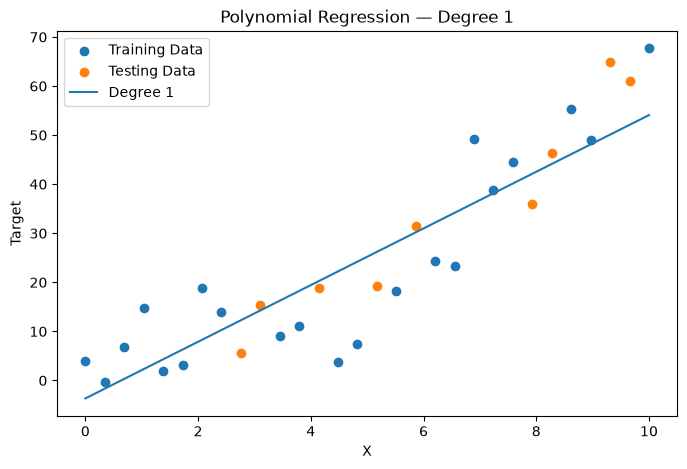

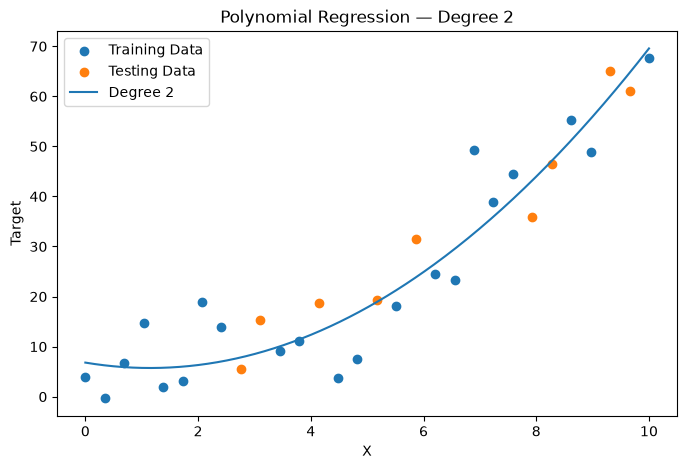

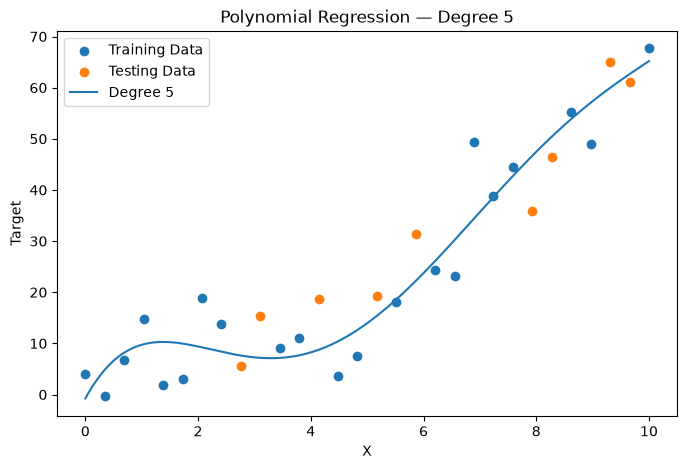

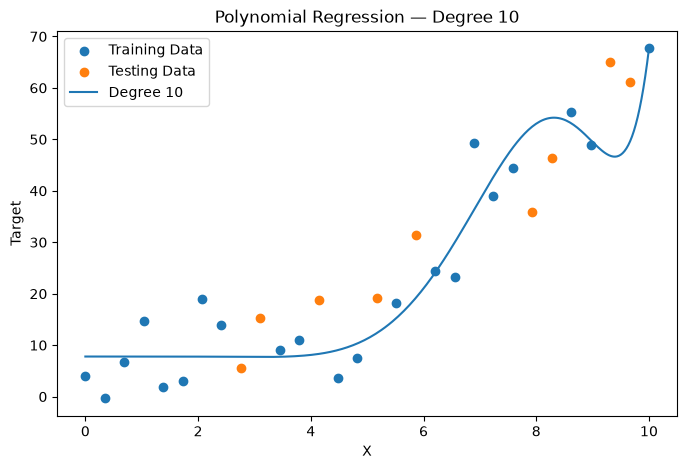

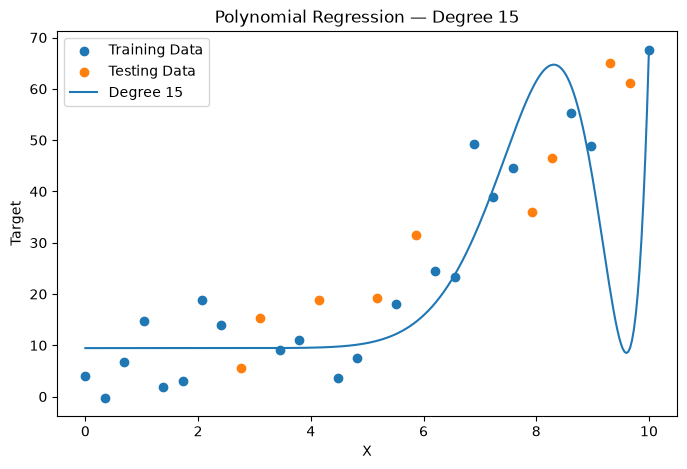

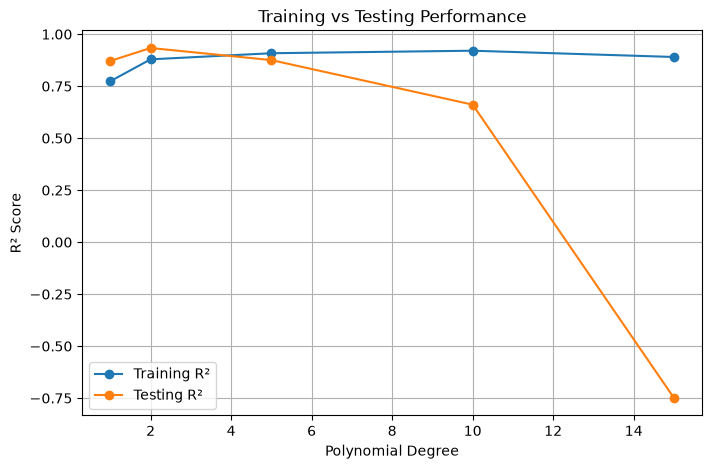

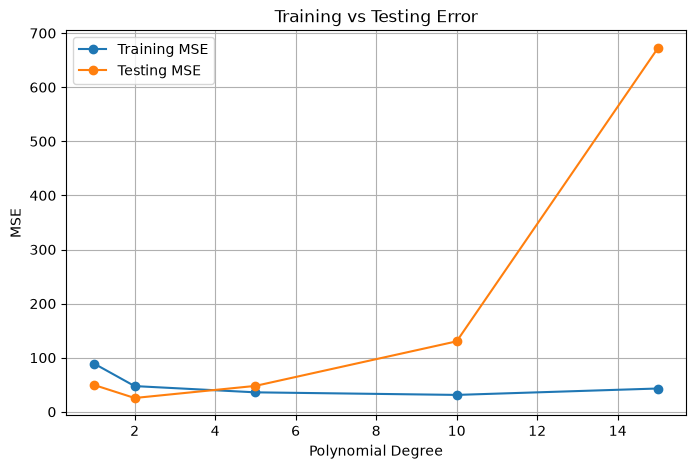


MODEL BEHAVIOR

Degree: 1
Training R²: 0.7740
Testing R² : 0.8714
R² Gap     : -0.0974
Better generalization

Degree: 2
Training R²: 0.8790
Testing R² : 0.9336
R² Gap     : -0.0546
Better generalization

Degree: 5
Training R²: 0.9084
Testing R² : 0.8754
R² Gap     : 0.0330
Better generalization

Degree: 10
Training R²: 0.9205
Testing R² : 0.6611
R² Gap     : 0.2595
Possible OVERFITTING

Degree: 15
Training R²: 0.8904
Testing R² : -0.7494
R² Gap     : 1.6398
Possible OVERFITTING

BEST GENERALIZING MODEL
Best polynomial degree: 2
Best Test R²: 0.9336

DAY 42 SUMMARY

Today I practiced:

✓ Underfitting
✓ Overfitting
✓ Model complexity
✓ Polynomial Regression
✓ Train/Test performance
✓ Training R²
✓ Testing R²
✓ Training MSE
✓ Testing MSE
✓ Model complexity experiments
✓ Generalization
✓ Visual model comparison

Key idea:

A model that performs extremely well on
training data may still perform poorly
on unseen data.

The goal is not to memorize the training data.

The goal is to generaliz

In [1]:
# ============================================================
# DAY 42/84 — OVERFITTING VS UNDERFITTING
# HANDS-ON MACHINE LEARNING
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score


# ============================================================
# 1. CREATE DATASET
# ============================================================

np.random.seed(42)

X = np.linspace(0, 10, 30).reshape(-1, 1)

y = (
    2 * X.flatten()
    + 0.5 * X.flatten() ** 2
    + np.random.normal(0, 8, 30)
)


print("=" * 60)
print("DATASET")
print("=" * 60)

print("Number of samples:", len(X))
print("X shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# 2. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

print("\n" + "=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))


# ============================================================
# 3. TRY DIFFERENT POLYNOMIAL DEGREES
# ============================================================

degrees = [1, 2, 5, 10, 15]

results = []


for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    # Train
    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Metrics
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    train_mse = mean_squared_error(
        y_train,
        train_pred
    )

    test_mse = mean_squared_error(
        y_test,
        test_pred
    )

    results.append(
        (
            degree,
            train_r2,
            test_r2,
            train_mse,
            test_mse
        )
    )


# ============================================================
# 4. DISPLAY RESULTS
# ============================================================

print("\n" + "=" * 60)
print("MODEL COMPLEXITY EXPERIMENT")
print("=" * 60)

print(
    f"{'Degree':<10}"
    f"{'Train R²':<15}"
    f"{'Test R²':<15}"
    f"{'Train MSE':<15}"
    f"{'Test MSE':<15}"
)

print("-" * 70)

for result in results:

    degree, train_r2, test_r2, train_mse, test_mse = result

    print(
        f"{degree:<10}"
        f"{train_r2:<15.4f}"
        f"{test_r2:<15.4f}"
        f"{train_mse:<15.2f}"
        f"{test_mse:<15.2f}"
    )


# ============================================================
# 5. VISUALIZE DIFFERENT MODEL COMPLEXITIES
# ============================================================

X_curve = np.linspace(
    X.min(),
    X.max(),
    300
).reshape(-1, 1)


for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    y_curve = model.predict(X_curve)

    plt.figure(figsize=(8, 5))

    plt.scatter(
        X_train,
        y_train,
        label="Training Data"
    )

    plt.scatter(
        X_test,
        y_test,
        label="Testing Data"
    )

    plt.plot(
        X_curve,
        y_curve,
        label=f"Degree {degree}"
    )

    plt.xlabel("X")
    plt.ylabel("Target")
    plt.title(
        f"Polynomial Regression — Degree {degree}"
    )

    plt.legend()
    plt.show()


# ============================================================
# 6. TRAINING VS TESTING R²
# ============================================================

train_r2_scores = [
    result[1]
    for result in results
]

test_r2_scores = [
    result[2]
    for result in results
]


plt.figure(figsize=(8, 5))

plt.plot(
    degrees,
    train_r2_scores,
    marker="o",
    label="Training R²"
)

plt.plot(
    degrees,
    test_r2_scores,
    marker="o",
    label="Testing R²"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("R² Score")
plt.title("Training vs Testing Performance")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 7. TRAINING VS TESTING MSE
# ============================================================

train_mse_scores = [
    result[3]
    for result in results
]

test_mse_scores = [
    result[4]
    for result in results
]


plt.figure(figsize=(8, 5))

plt.plot(
    degrees,
    train_mse_scores,
    marker="o",
    label="Training MSE"
)

plt.plot(
    degrees,
    test_mse_scores,
    marker="o",
    label="Testing MSE"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("MSE")
plt.title("Training vs Testing Error")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 8. IDENTIFY MODEL BEHAVIOR
# ============================================================

print("\n" + "=" * 60)
print("MODEL BEHAVIOR")
print("=" * 60)

for result in results:

    degree, train_r2, test_r2, train_mse, test_mse = result

    gap = train_r2 - test_r2

    print(f"\nDegree: {degree}")

    print(f"Training R²: {train_r2:.4f}")
    print(f"Testing R² : {test_r2:.4f}")
    print(f"R² Gap     : {gap:.4f}")

    if train_r2 < 0.7 and test_r2 < 0.7:

        print("Possible UNDERFITTING")

    elif gap > 0.2:

        print("Possible OVERFITTING")

    else:

        print("Better generalization")


# ============================================================
# 9. FIND BEST TEST MODEL
# ============================================================

best_result = max(
    results,
    key=lambda result: result[2]
)

best_degree = best_result[0]
best_test_r2 = best_result[2]

print("\n" + "=" * 60)
print("BEST GENERALIZING MODEL")
print("=" * 60)

print("Best polynomial degree:", best_degree)
print("Best Test R²:", round(best_test_r2, 4))


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("DAY 42 SUMMARY")
print("=" * 60)

print("""
Today I practiced:

✓ Underfitting
✓ Overfitting
✓ Model complexity
✓ Polynomial Regression
✓ Train/Test performance
✓ Training R²
✓ Testing R²
✓ Training MSE
✓ Testing MSE
✓ Model complexity experiments
✓ Generalization
✓ Visual model comparison

Key idea:

A model that performs extremely well on
training data may still perform poorly
on unseen data.

The goal is not to memorize the training data.

The goal is to generalize well.
""")

DATASET
Samples : 100
Features: 1


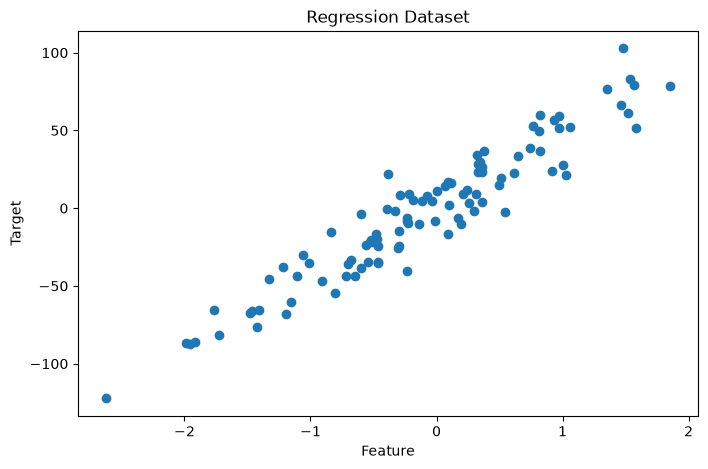


SINGLE TRAIN / TEST SPLIT
Test R² : 0.8742
Test MSE: 234.4550

5-FOLD CROSS-VALIDATION
Fold 1: R² = 0.8742
Fold 2: R² = 0.9397
Fold 3: R² = 0.9398
Fold 4: R² = 0.8620
Fold 5: R² = 0.8236

CROSS-VALIDATION SUMMARY
Mean CV R²: 0.8878
Std CV R² : 0.0455


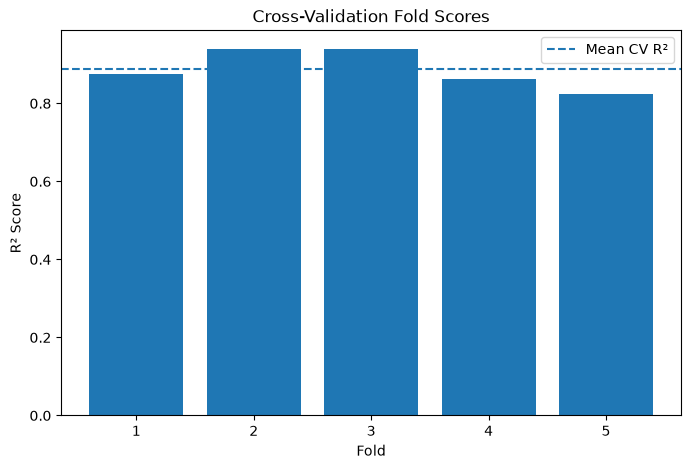


DIFFERENT K VALUES
K=3   Mean R²=0.8894 Std=0.0342
K=5   Mean R²=0.8878 Std=0.0455
K=7   Mean R²=0.8770 Std=0.0608
K=10  Mean R²=0.8789 Std=0.0697

MODEL COMPARISON USING CROSS-VALIDATION
Degree 1  → Mean R²: 0.8945 | Std: 0.0451
Degree 2  → Mean R²: 0.8942 | Std: 0.0449
Degree 3  → Mean R²: 0.8896 | Std: 0.0447
Degree 5  → Mean R²: 0.8845 | Std: 0.0473
Degree 10 → Mean R²: -2.2824 | Std: 5.6328

FINAL TAKEAWAY

A single train/test split depends on one particular split.

Cross-validation evaluates the model across
multiple different validation folds.

This gives us a more reliable estimate of
how consistently the model performs.

Mean CV score → average performance
Std CV score  → variation across folds



In [2]:
# ============================================================
# DAY 43/84 — CROSS-VALIDATION
# HANDS-ON MACHINE LEARNING
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score
)
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_squared_error


# ============================================================
# 1. CREATE DATASET
# ============================================================

X, y = make_regression(
    n_samples=100,
    n_features=1,
    noise=15,
    random_state=42
)

print("=" * 60)
print("DATASET")
print("=" * 60)

print("Samples :", X.shape[0])
print("Features:", X.shape[1])


# ============================================================
# 2. VISUALIZE DATA
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(X, y)

plt.xlabel("Feature")
plt.ylabel("Target")
plt.title("Regression Dataset")

plt.show()


# ============================================================
# 3. NORMAL TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

predictions = model.predict(X_test)

test_r2 = r2_score(
    y_test,
    predictions
)

test_mse = mean_squared_error(
    y_test,
    predictions
)

print("\n" + "=" * 60)
print("SINGLE TRAIN / TEST SPLIT")
print("=" * 60)

print(f"Test R² : {test_r2:.4f}")
print(f"Test MSE: {test_mse:.4f}")


# ============================================================
# 4. K-FOLD CROSS-VALIDATION
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

print("\n" + "=" * 60)
print("5-FOLD CROSS-VALIDATION")
print("=" * 60)

for fold, score in enumerate(cv_scores, start=1):

    print(
        f"Fold {fold}: R² = {score:.4f}"
    )


# ============================================================
# 5. MEAN AND STANDARD DEVIATION
# ============================================================

mean_cv_score = cv_scores.mean()
std_cv_score = cv_scores.std()

print("\n" + "=" * 60)
print("CROSS-VALIDATION SUMMARY")
print("=" * 60)

print(
    f"Mean CV R²: {mean_cv_score:.4f}"
)

print(
    f"Std CV R² : {std_cv_score:.4f}"
)


# ============================================================
# 6. VISUALIZE FOLD SCORES
# ============================================================

plt.figure(figsize=(8, 5))

fold_numbers = np.arange(
    1,
    len(cv_scores) + 1
)

plt.bar(
    fold_numbers,
    cv_scores
)

plt.axhline(
    mean_cv_score,
    linestyle="--",
    label="Mean CV R²"
)

plt.xlabel("Fold")
plt.ylabel("R² Score")
plt.title("Cross-Validation Fold Scores")

plt.legend()

plt.show()


# ============================================================
# 7. COMPARE DIFFERENT K VALUES
# ============================================================

k_values = [3, 5, 7, 10]

k_means = []
k_stds = []


for k in k_values:

    kf = KFold(
        n_splits=k,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="r2"
    )

    k_means.append(
        scores.mean()
    )

    k_stds.append(
        scores.std()
    )


print("\n" + "=" * 60)
print("DIFFERENT K VALUES")
print("=" * 60)

for k, mean, std in zip(
    k_values,
    k_means,
    k_stds
):

    print(
        f"K={k:<3} "
        f"Mean R²={mean:.4f} "
        f"Std={std:.4f}"
    )


# ============================================================
# 8. POLYNOMIAL MODEL COMPARISON
# ============================================================

degrees = [1, 2, 3, 5, 10]

print("\n" + "=" * 60)
print("MODEL COMPARISON USING CROSS-VALIDATION")
print("=" * 60)

for degree in degrees:

    polynomial_model = make_pipeline(
        PolynomialFeatures(
            degree=degree
        ),
        LinearRegression()
    )

    scores = cross_val_score(
        polynomial_model,
        X,
        y,
        cv=5,
        scoring="r2"
    )

    print(
        f"Degree {degree:<2} → "
        f"Mean R²: {scores.mean():.4f} | "
        f"Std: {scores.std():.4f}"
    )


# ============================================================
# 9. FINAL COMPARISON
# ============================================================

print("\n" + "=" * 60)
print("FINAL TAKEAWAY")
print("=" * 60)

print("""
A single train/test split depends on one particular split.

Cross-validation evaluates the model across
multiple different validation folds.

This gives us a more reliable estimate of
how consistently the model performs.

Mean CV score → average performance
Std CV score  → variation across folds
""")

DATASET
Samples : 100
Features: 5

MODEL COMPARISON
Linear Regression R²: 0.9781
Ridge Regression  R²: 0.9775
Lasso Regression  R²: 0.9781

COEFFICIENT COMPARISON
Feature     Linear         Ridge          Lasso          
-------------------------------------------------------
Feature 1   62.4667        61.7427        62.3828        
Feature 2   98.2935        96.8003        98.1686        
Feature 3   57.6077        56.4237        57.4438        
Feature 4   54.0052        53.3167        53.9033        
Feature 5   36.3386        36.0554        36.2545        

RIDGE ALPHA EXPERIMENT
Alpha=0.01   R²=0.9781
Alpha=0.1    R²=0.9781
Alpha=1      R²=0.9775
Alpha=10     R²=0.9600
Alpha=100    R²=0.6447

LASSO ALPHA EXPERIMENT
Alpha=0.001  R²=0.9781
Alpha=0.01   R²=0.9781
Alpha=0.1    R²=0.9781
Alpha=1      R²=0.9778
Alpha=10     R²=0.9527


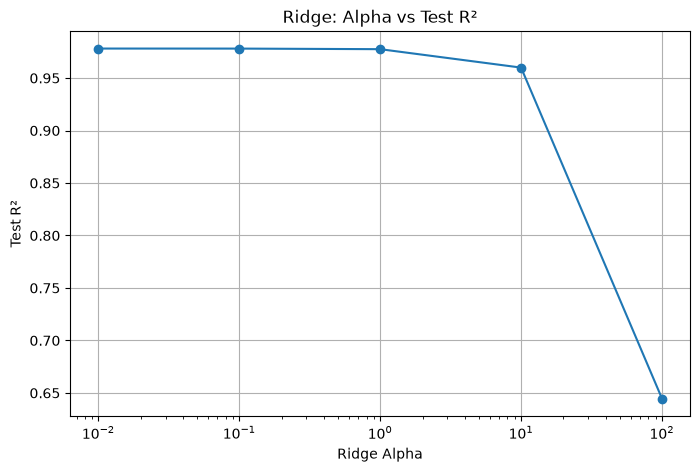

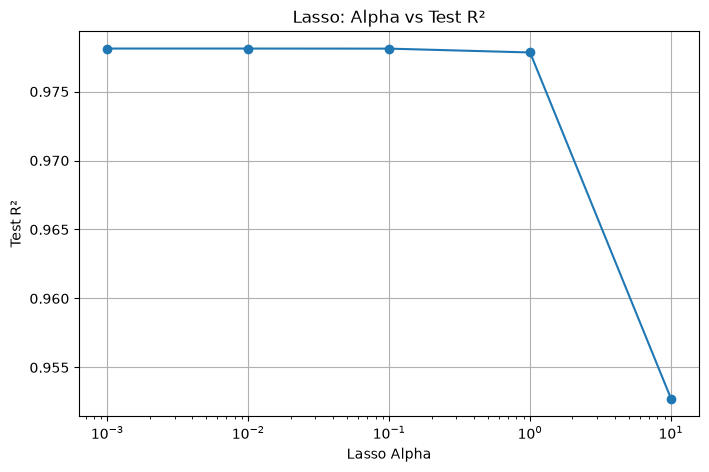


LASSO FEATURE SELECTION
Total features: 5
Zero coefficients: 0
Non-zero coefficients: 5

POLYNOMIAL REGRESSION + REGULARIZATION
Polynomial + Linear            R² = 0.1949
Polynomial + Ridge             R² = 0.1893
Polynomial + Lasso             R² = 0.2077

DAY 44 SUMMARY

Today I practiced:

✓ Regularization
✓ Ridge Regression
✓ Lasso Regression
✓ Alpha parameter
✓ Coefficient comparison
✓ Ridge alpha experiment
✓ Lasso alpha experiment
✓ Lasso feature selection
✓ Polynomial Regression + Regularization

Key idea:

Regularization adds a penalty to model complexity.

Ridge shrinks coefficients.

Lasso can shrink some coefficients all the way to zero.

The goal is to reduce unnecessary complexity
and improve generalization.



c:\Users\Abdul Rahman\OneDrive\Desktop\Abdulprac\AI-Engineer-Journey\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:840: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.530313e+05, tolerance: 1.538e+02
  model = cd_fast.enet_coordinate_descent(


In [3]:
# ============================================================
# DAY 44/84 — REGULARIZATION
# RIDGE vs LASSO
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.metrics import r2_score


# ============================================================
# 1. CREATE DATASET
# ============================================================

np.random.seed(42)

X, y = make_regression(
    n_samples=100,
    n_features=5,
    noise=20,
    random_state=42
)


print("=" * 60)
print("DATASET")
print("=" * 60)

print("Samples :", X.shape[0])
print("Features:", X.shape[1])


# ============================================================
# 2. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ============================================================
# 3. BASELINE LINEAR REGRESSION
# ============================================================

linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(
    X_test
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)


# ============================================================
# 4. RIDGE REGRESSION
# ============================================================

ridge_model = Ridge(
    alpha=1.0
)

ridge_model.fit(
    X_train,
    y_train
)

ridge_predictions = ridge_model.predict(
    X_test
)

ridge_r2 = r2_score(
    y_test,
    ridge_predictions
)


# ============================================================
# 5. LASSO REGRESSION
# ============================================================

lasso_model = Lasso(
    alpha=0.1,
    max_iter=10000
)

lasso_model.fit(
    X_train,
    y_train
)

lasso_predictions = lasso_model.predict(
    X_test
)

lasso_r2 = r2_score(
    y_test,
    lasso_predictions
)


# ============================================================
# 6. MODEL COMPARISON
# ============================================================

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(
    f"Linear Regression R²: {linear_r2:.4f}"
)

print(
    f"Ridge Regression  R²: {ridge_r2:.4f}"
)

print(
    f"Lasso Regression  R²: {lasso_r2:.4f}"
)


# ============================================================
# 7. COMPARE COEFFICIENTS
# ============================================================

print("\n" + "=" * 60)
print("COEFFICIENT COMPARISON")
print("=" * 60)

print(
    f"{'Feature':<12}"
    f"{'Linear':<15}"
    f"{'Ridge':<15}"
    f"{'Lasso':<15}"
)

print("-" * 55)

for i in range(X.shape[1]):

    print(
        f"Feature {i+1:<4}"
        f"{linear_model.coef_[i]:<15.4f}"
        f"{ridge_model.coef_[i]:<15.4f}"
        f"{lasso_model.coef_[i]:<15.4f}"
    )


# ============================================================
# 8. EXPERIMENT WITH RIDGE ALPHA
# ============================================================

ridge_alphas = [
    0.01,
    0.1,
    1,
    10,
    100
]

ridge_scores = []


print("\n" + "=" * 60)
print("RIDGE ALPHA EXPERIMENT")
print("=" * 60)

for alpha in ridge_alphas:

    model = Ridge(
        alpha=alpha
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    score = r2_score(
        y_test,
        predictions
    )

    ridge_scores.append(score)

    print(
        f"Alpha={alpha:<6} "
        f"R²={score:.4f}"
    )


# ============================================================
# 9. EXPERIMENT WITH LASSO ALPHA
# ============================================================

lasso_alphas = [
    0.001,
    0.01,
    0.1,
    1,
    10
]

lasso_scores = []


print("\n" + "=" * 60)
print("LASSO ALPHA EXPERIMENT")
print("=" * 60)

for alpha in lasso_alphas:

    model = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_test
    )

    score = r2_score(
        y_test,
        predictions
    )

    lasso_scores.append(score)

    print(
        f"Alpha={alpha:<6} "
        f"R²={score:.4f}"
    )


# ============================================================
# 10. PLOT RIDGE PERFORMANCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.semilogx(
    ridge_alphas,
    ridge_scores,
    marker="o"
)

plt.xlabel("Ridge Alpha")
plt.ylabel("Test R²")
plt.title("Ridge: Alpha vs Test R²")

plt.grid(True)

plt.show()


# ============================================================
# 11. PLOT LASSO PERFORMANCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.semilogx(
    lasso_alphas,
    lasso_scores,
    marker="o"
)

plt.xlabel("Lasso Alpha")
plt.ylabel("Test R²")
plt.title("Lasso: Alpha vs Test R²")

plt.grid(True)

plt.show()


# ============================================================
# 12. COUNT ZERO LASSO COEFFICIENTS
# ============================================================

zero_coefficients = np.sum(
    lasso_model.coef_ == 0
)

print("\n" + "=" * 60)
print("LASSO FEATURE SELECTION")
print("=" * 60)

print(
    "Total features:",
    len(lasso_model.coef_)
)

print(
    "Zero coefficients:",
    zero_coefficients
)

print(
    "Non-zero coefficients:",
    np.count_nonzero(
        lasso_model.coef_
    )
)


# ============================================================
# 13. POLYNOMIAL REGRESSION + REGULARIZATION
# ============================================================

degrees = 10

models = {
    "Polynomial + Linear": make_pipeline(
        PolynomialFeatures(degree=degrees),
        LinearRegression()
    ),

    "Polynomial + Ridge": make_pipeline(
        PolynomialFeatures(degree=degrees),
        Ridge(alpha=10)
    ),

    "Polynomial + Lasso": make_pipeline(
        PolynomialFeatures(degree=degrees),
        Lasso(
            alpha=0.1,
            max_iter=20000
        )
    )
}


print("\n" + "=" * 60)
print("POLYNOMIAL REGRESSION + REGULARIZATION")
print("=" * 60)

for name, model in models.items():

    model.fit(
        X_train[:, [0]],
        y_train
    )

    predictions = model.predict(
        X_test[:, [0]]
    )

    score = r2_score(
        y_test,
        predictions
    )

    print(
        f"{name:<30} "
        f"R² = {score:.4f}"
    )


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("DAY 44 SUMMARY")
print("=" * 60)

print("""
Today I practiced:

✓ Regularization
✓ Ridge Regression
✓ Lasso Regression
✓ Alpha parameter
✓ Coefficient comparison
✓ Ridge alpha experiment
✓ Lasso alpha experiment
✓ Lasso feature selection
✓ Polynomial Regression + Regularization

Key idea:

Regularization adds a penalty to model complexity.

Ridge shrinks coefficients.

Lasso can shrink some coefficients all the way to zero.

The goal is to reduce unnecessary complexity
and improve generalization.
""")